In [70]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [71]:
crypto_list = ["ADA", "BCH", "BNB", "BTC", "ETC", "ETH", "LINK", "LTC", "XLM", "XRP"]
df_list = {}

for crypto in crypto_list:
    print(crypto)
    df_list[crypto] = pd.read_csv(f"{crypto}-USDT.csv")
    df_list[crypto]['date'] = pd.to_datetime(df_list[crypto]['date'], unit='ms')
    # set the date as the index
    df_list[crypto].set_index('date', inplace=True)
    
    


ADA
BCH
BNB
BTC
ETC
ETH
LINK
LTC
XLM
XRP


In [72]:
df_list['ADA']

,open,high,low,close,volume
date,,,,,
2018-04-17 04:00:00,0.25551,0.28800,0.25551,0.26664,8143693.23
2018-04-17 05:00:00,0.26660,0.27798,0.26010,0.26200,8317923.61
2018-04-17 06:00:00,0.26221,0.26396,0.24800,0.25664,8420095.41
2018-04-17 07:00:00,0.25662,0.26300,0.25489,0.25698,4686043.91
2018-04-17 08:00:00,0.25636,0.25998,0.25229,0.25631,3510038.13
...,...,...,...,...,...
2023-07-03 06:00:00,0.29330,0.29350,0.29080,0.29230,2758504.10
2023-07-03 07:00:00,0.29240,0.29580,0.29220,0.29420,2834458.10
2023-07-03 08:00:00,0.29430,0.29560,0.29340,0.29480,3282098.30


In [73]:
df_list['BTC'].describe()

,open,high,low,close,volume
count,51409.000000,51409.000000,51409.000000,51409.000000,51409.000000
mean,19954.063599,20063.211440,19838.180510,19954.559247,3202.002562
std,16122.044229,16211.788792,16027.092813,16121.972048,4474.783274
min,2870.900000,2950.000000,2817.000000,2919.000000,0.000000
25%,7557.910000,7600.000000,7521.000000,7558.480000,1015.423816
50%,11543.260000,11606.030000,11475.000000,11545.780000,1770.465966
75%,29489.460000,29619.790000,29353.270000,29493.120000,3480.848823
max,68635.120000,69000.000000,68451.190000,68633.690000,137207.188600


In [74]:
df_list['BTC'].index.nunique(), len(df_list['BTC'])




(51383, 51409)

In [75]:
duplicated_data = df_list['BTC'].index.duplicated(keep='last') # Tht is how we can check for duplicates in the index. The keep parameter specifies which duplicates to mark as True.
df_list['BTC'][duplicated_data] # This will return the rows with duplicated index values.
df_list['BTC'] = df_list['BTC'][~duplicated_data] # This will remove the duplicated rows from the DataFrame, keeping only the last occurrence of each duplicated index value.


In [76]:
crypto_list = ["ADA", "BCH", "BNB", "BTC", "ETC", "ETH", "LINK", "LTC", "XLM", "XRP"]
df_list = {}

for crypto in crypto_list:
    print(crypto)
    df_list[crypto] = pd.read_csv(f"{crypto}-USDT.csv")
    df_list[crypto]['date'] = pd.to_datetime(df_list[crypto]['date'], unit='ms')
    # set the date as the index
    df_list[crypto].set_index('date', inplace=True)
    duplicated_data = df_list[crypto].index.duplicated(keep='last')
    df_list[crypto][duplicated_data]
    df_list[crypto] = df_list[crypto][~duplicated_data] 
    

ADA
BCH
BNB
BTC
ETC
ETH
LINK
LTC
XLM
XRP


In [77]:
df_list['ADA'].index.nunique(), len(df_list['ADA'])


(45591, 45591)

In [78]:
df = pd.DataFrame()
for crypto in df_list:
    print(crypto)
    df[crypto] = df_list[crypto]['close'] # Creating a new DataFrame with the closing prices of each cryptocurrency.
    
    

ADA
BCH
BNB
BTC
ETC
ETH
LINK
LTC
XLM
XRP


In [79]:
df

,ADA,BCH,BNB,BTC,ETC,ETH,LINK,LTC,XLM,XRP
date,,,,,,,,,,
2018-04-17 04:00:00,0.26664,NaN,12.3000,8030.00,NaN,507.60,NaN,129.62,NaN,NaN
2018-04-17 05:00:00,0.26200,NaN,12.2916,7983.00,NaN,505.56,NaN,129.25,NaN,NaN
2018-04-17 06:00:00,0.25664,NaN,12.2720,8025.01,NaN,507.77,NaN,132.90,NaN,NaN
2018-04-17 07:00:00,0.25698,NaN,12.3982,8138.45,NaN,514.28,NaN,134.80,NaN,NaN
2018-04-17 08:00:00,0.25631,NaN,12.4000,8131.60,NaN,516.42,NaN,136.10,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
2023-07-03 06:00:00,0.29230,292.5,247.2000,30651.25,20.18,1947.85,6.563,111.88,0.1085,0.4824
2023-07-03 07:00:00,0.29420,295.3,249.5000,30667.19,20.34,1966.83,6.633,112.34,0.1093,0.4807
2023-07-03 08:00:00,0.29480,293.7,248.6000,30640.12,20.15,1960.02,6.618,110.66,0.1073,0.4838


In [80]:
df = df.dropna() # This will remove any rows with missing values (NaN) from the DataFrame and save the result back to the same DataFrame.


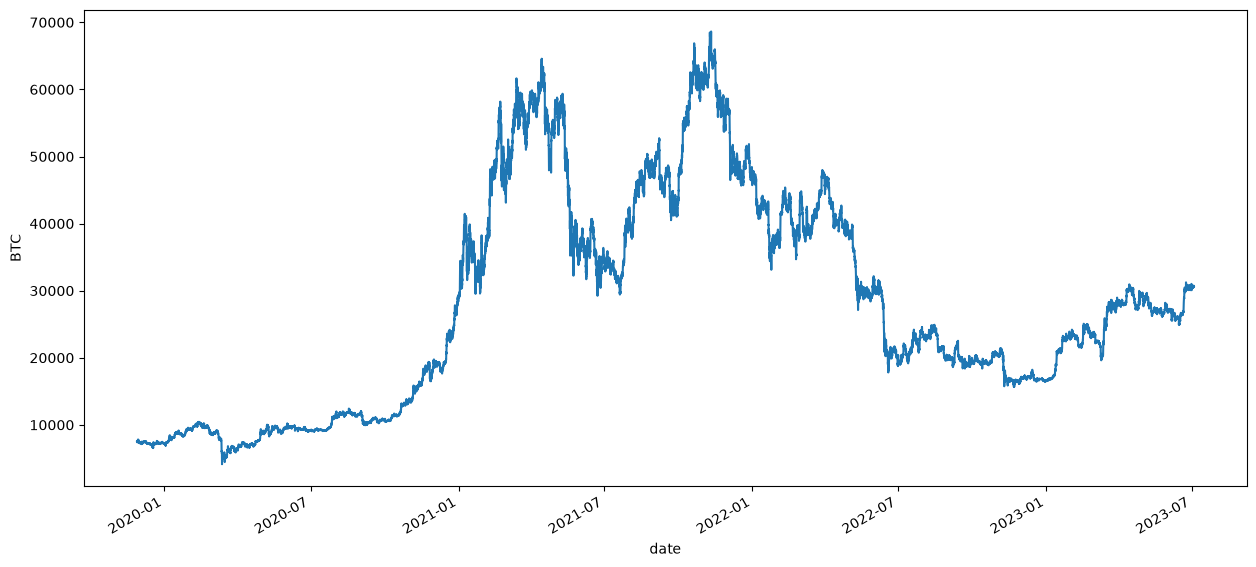

In [81]:
fig, ax = plt.subplots(figsize=(15, 7))
df['BTC'].plot(label='BTC')
ax.set_ylabel('BTC')
plt.show()

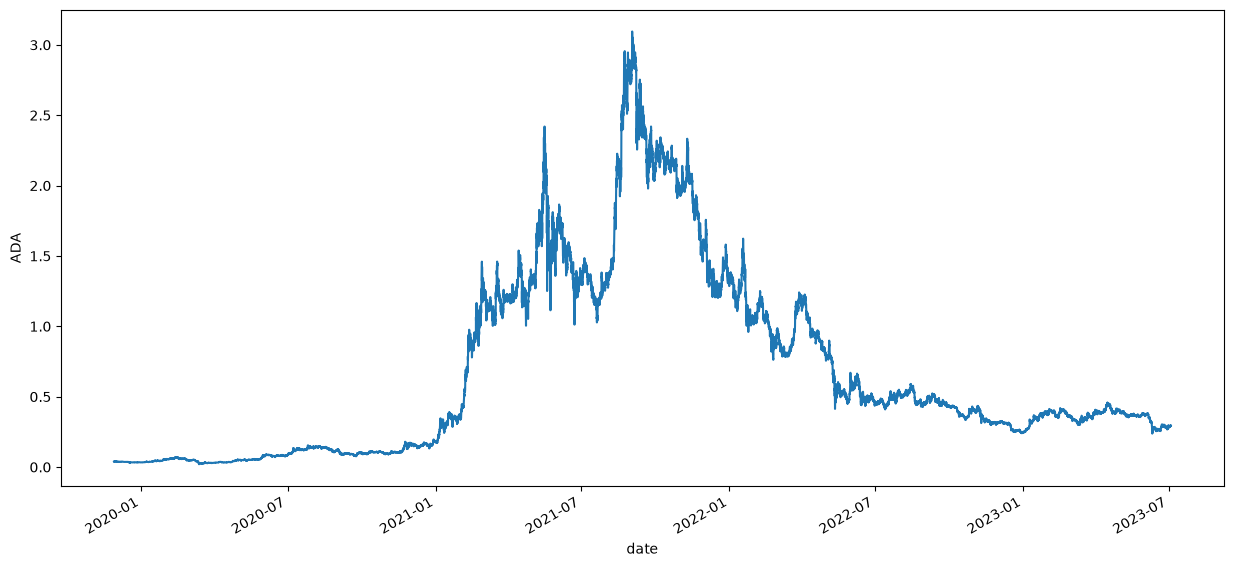

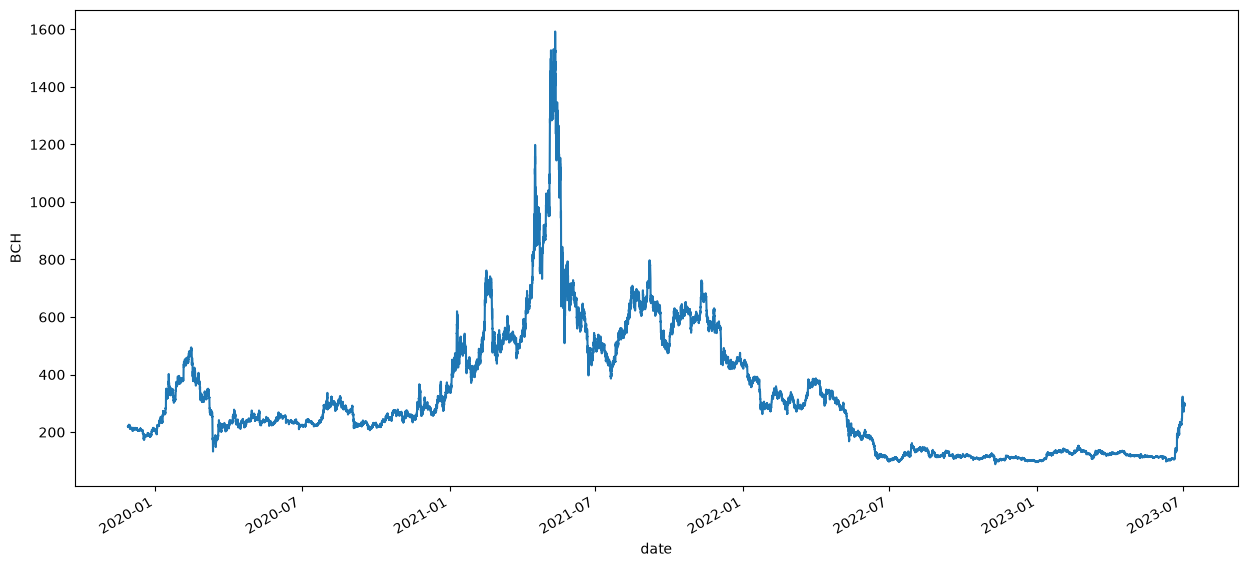

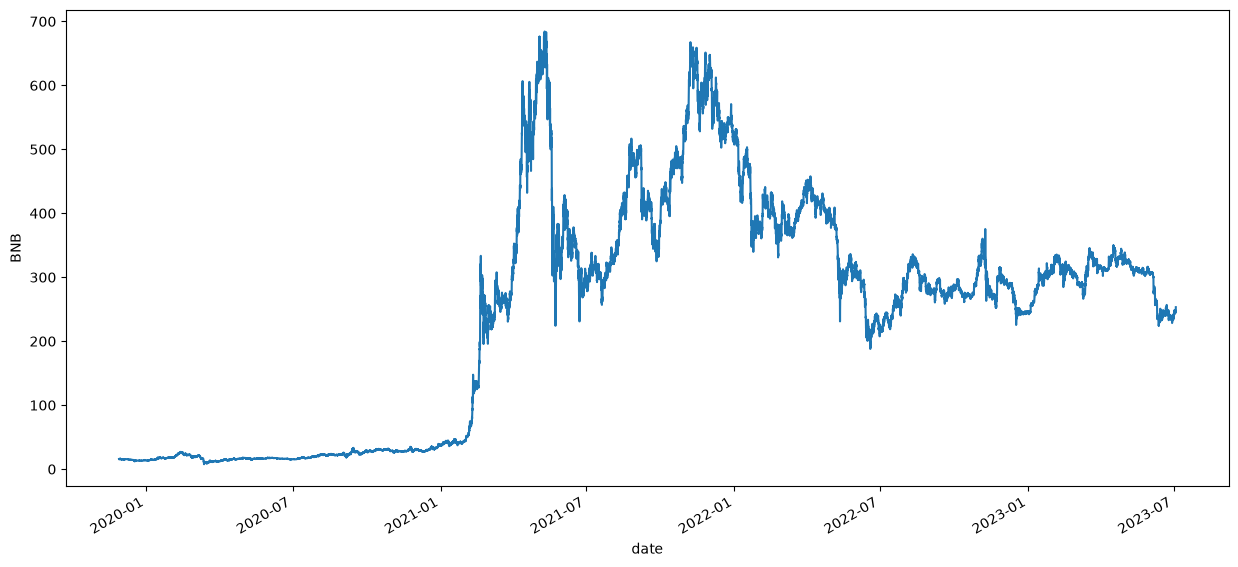

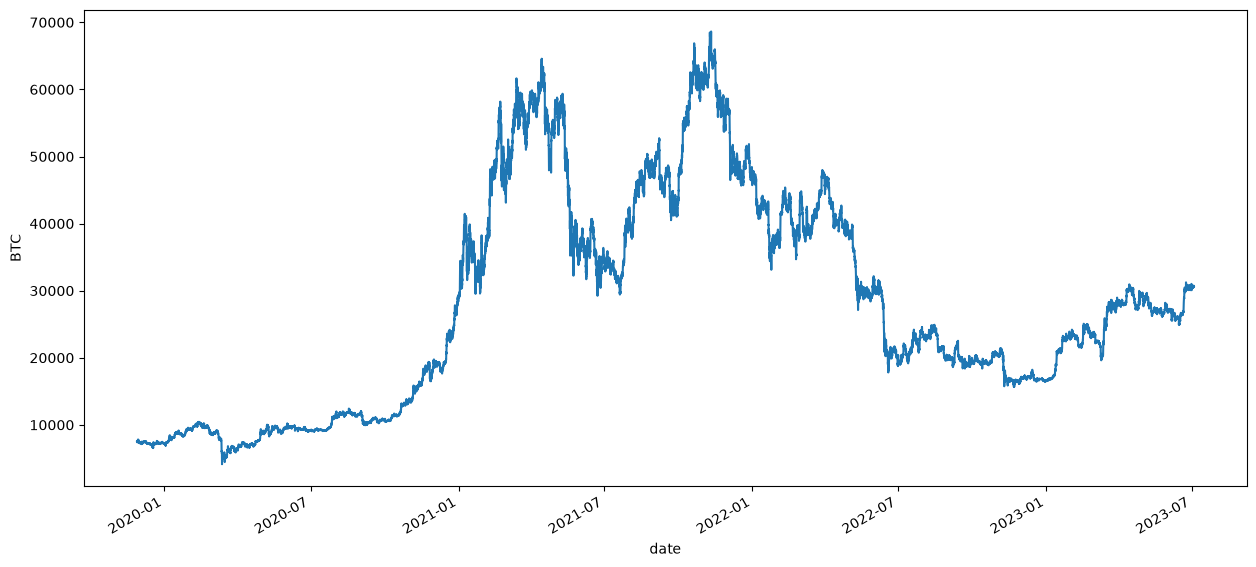

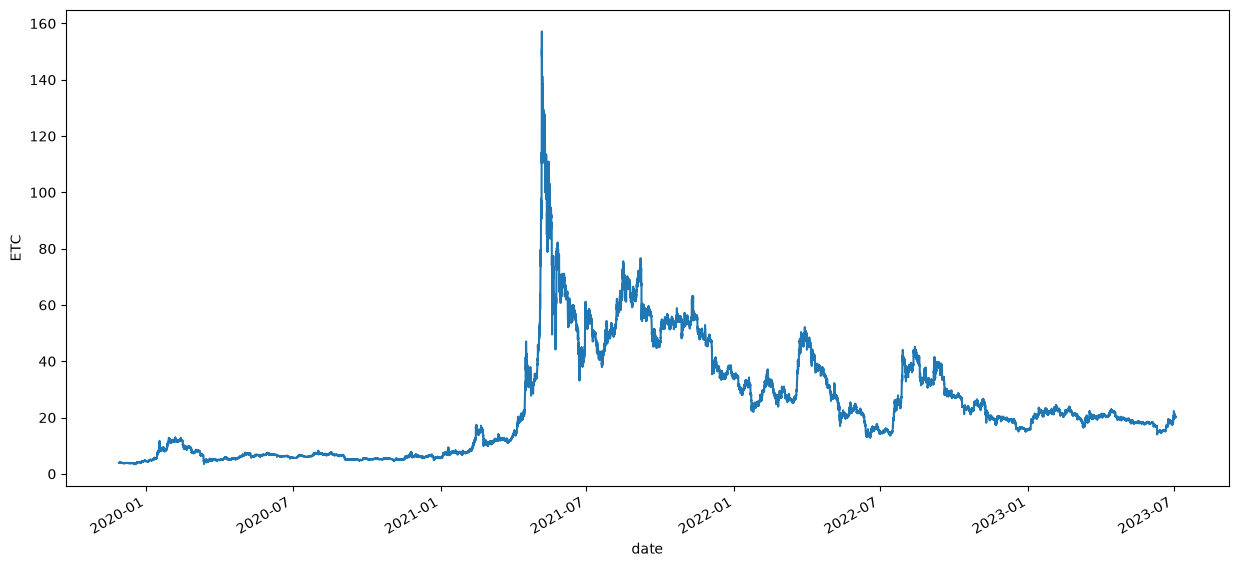

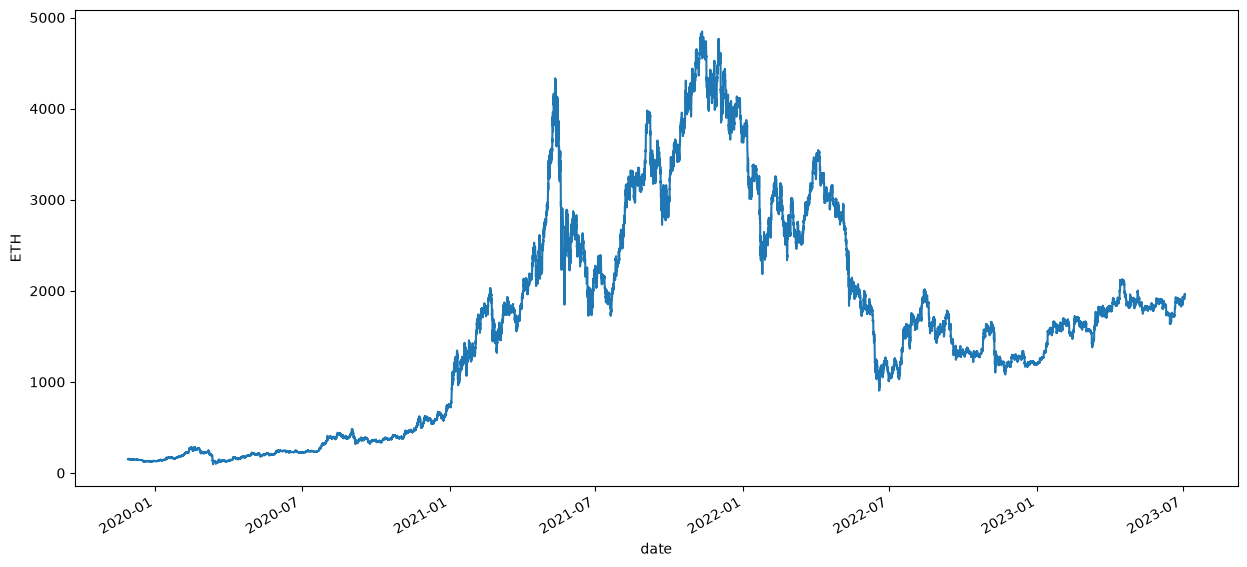

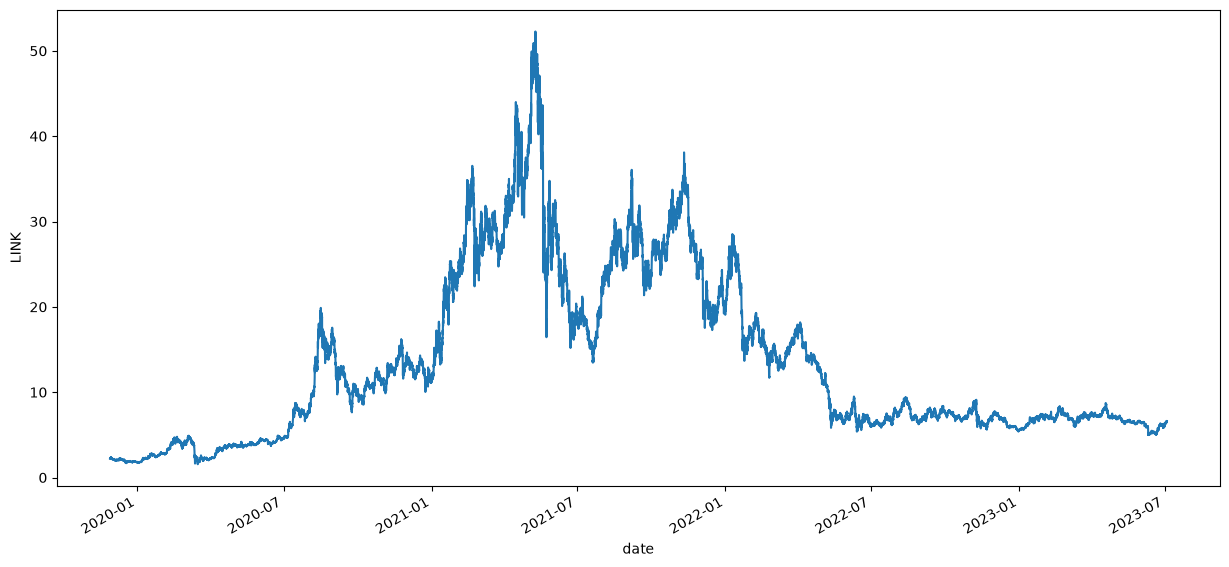

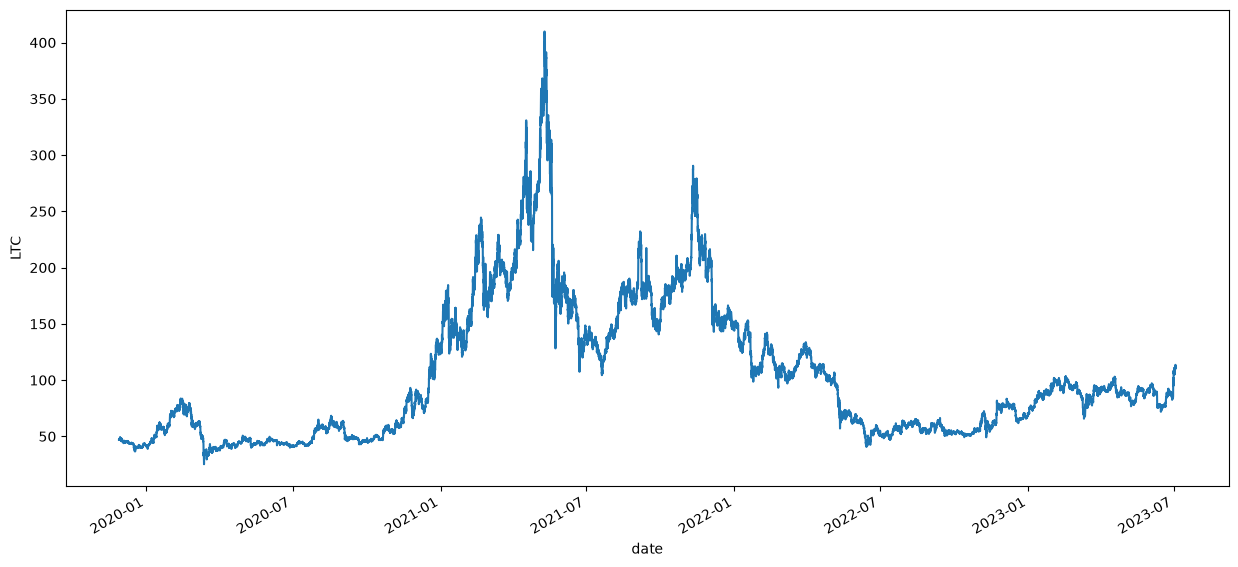

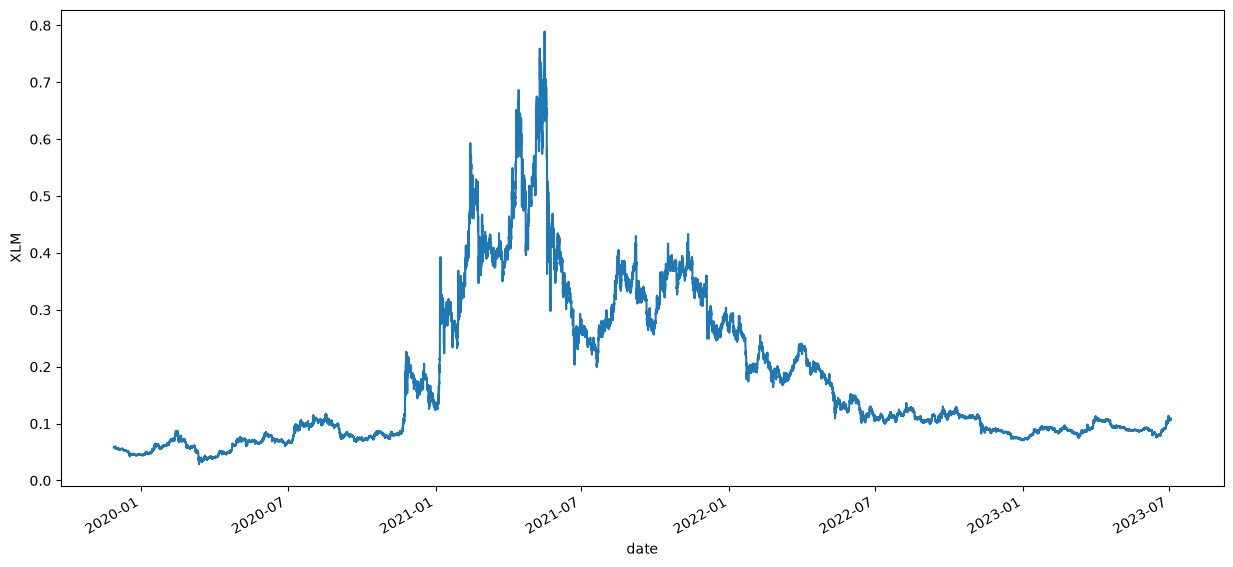

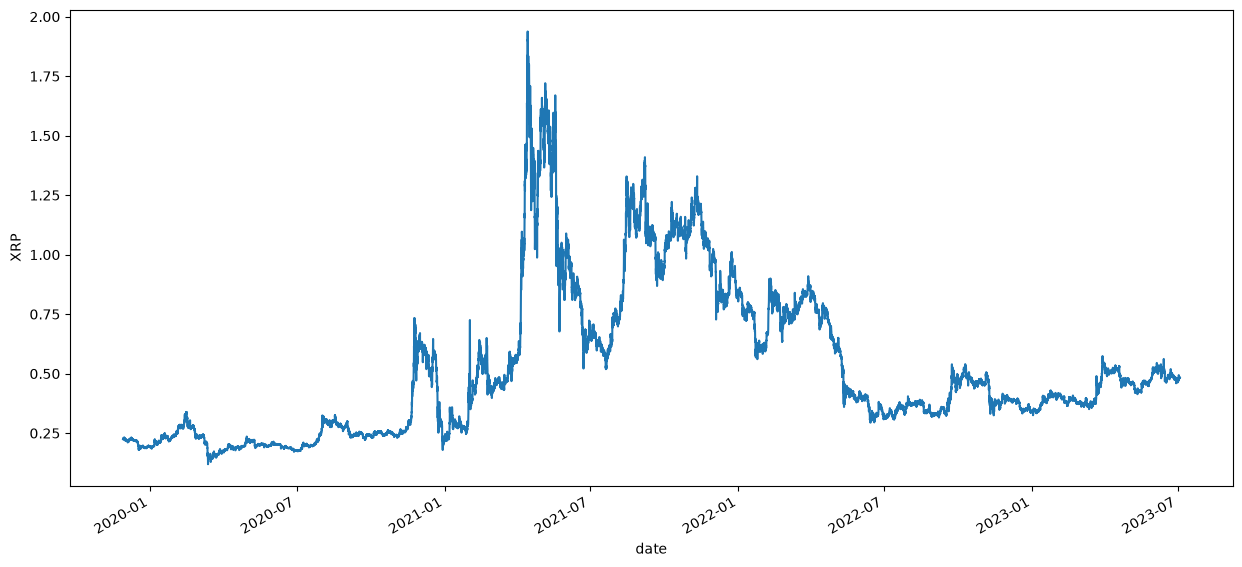

In [82]:
for column in df.columns:
    fig, ax = plt.subplots(figsize=(15, 7))
    df[column].plot(label=column)
    ax.set_ylabel(column)
    plt.show()

In [83]:
df.corr()

,ADA,BCH,BNB,BTC,ETC,ETH,LINK,LTC,XLM,XRP
ADA,1.000000,0.723569,0.782634,0.859911,0.848417,0.869297,0.819000,0.805404,0.803867,0.887277
BCH,0.723569,1.000000,0.430161,0.690909,0.638144,0.532628,0.890495,0.889421,0.896184,0.767310
BNB,0.782634,0.430161,1.000000,0.822675,0.800248,0.939650,0.610371,0.688569,0.619362,0.834212
BTC,0.859911,0.690909,0.822675,1.000000,0.680973,0.896195,0.860330,0.897080,0.870901,0.853319
ETC,0.848417,0.638144,0.800248,0.680973,1.000000,0.820675,0.659701,0.689580,0.662189,0.833492
ETH,0.869297,0.532628,0.939650,0.896195,0.820675,1.000000,0.700819,0.746219,0.686731,0.861432
LINK,0.819000,0.890495,0.610371,0.860330,0.659701,0.700819,1.000000,0.940221,0.960905,0.836123
LTC,0.805404,0.889421,0.688569,0.897080,0.689580,0.746219,0.940221,1.000000,0.953542,0.861605
XLM,0.803867,0.896184,0.619362,0.870901,0.662189,0.686731,0.960905,0.953542,1.000000,0.833596
XRP,0.887277,0.767310,0.834212,0.853319,0.833492,0.861432,0.836123,0.861605,0.833596,1.000000


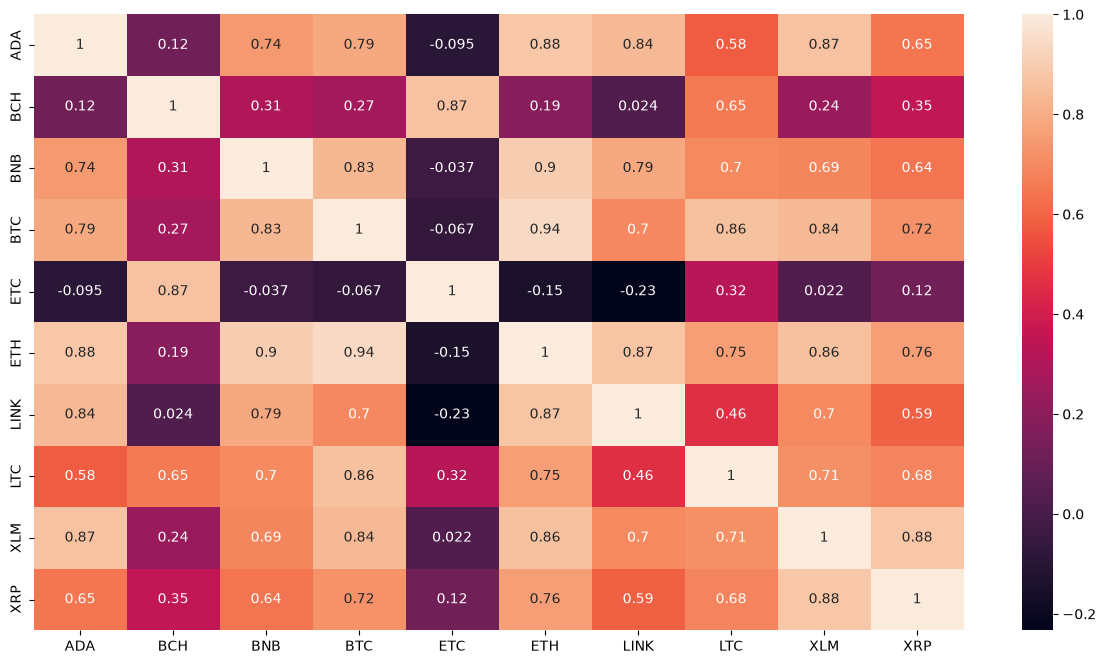

In [84]:
plt.figure(figsize=(15, 8))
sns.heatmap(df.loc['2020'].corr(), annot=True)
plt.show()

In [88]:
df_pct = df.pct_change() # This will calculate the percentage change between the current and a prior element in the DataFrame. 
# It is often used to calculate returns in financial data.
df_pct


,ADA,BCH,BNB,BTC,ETC,ETH,LINK,LTC,XLM,XRP
date,,,,,,,,,,
2019-11-28 10:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-11-28 11:00:00,0.006216,0.000274,0.000523,0.000128,0.003076,0.002911,0.007111,0.002752,0.000172,0.003151
2019-11-28 12:00:00,-0.009009,-0.006894,-0.014893,-0.004736,-0.007933,-0.005146,-0.015321,-0.010980,-0.002578,-0.004602
2019-11-28 13:00:00,-0.001039,0.003494,0.000141,0.001552,0.004675,0.001525,-0.003247,0.001494,-0.002413,-0.000667
2019-11-28 14:00:00,0.007540,0.001741,0.004150,0.000515,0.001551,-0.000861,0.010588,0.002558,0.002418,0.001423
...,...,...,...,...,...,...,...,...,...,...
2023-07-03 06:00:00,-0.003070,-0.015483,0.002027,-0.000729,-0.004440,0.001172,-0.004701,-0.004715,0.001847,0.000207
2023-07-03 07:00:00,0.006500,0.009573,0.009304,0.000520,0.007929,0.009744,0.010666,0.004112,0.007373,-0.003524
2023-07-03 08:00:00,0.002039,-0.005418,-0.003607,-0.000883,-0.009341,-0.003462,-0.002261,-0.014955,-0.018298,0.006449


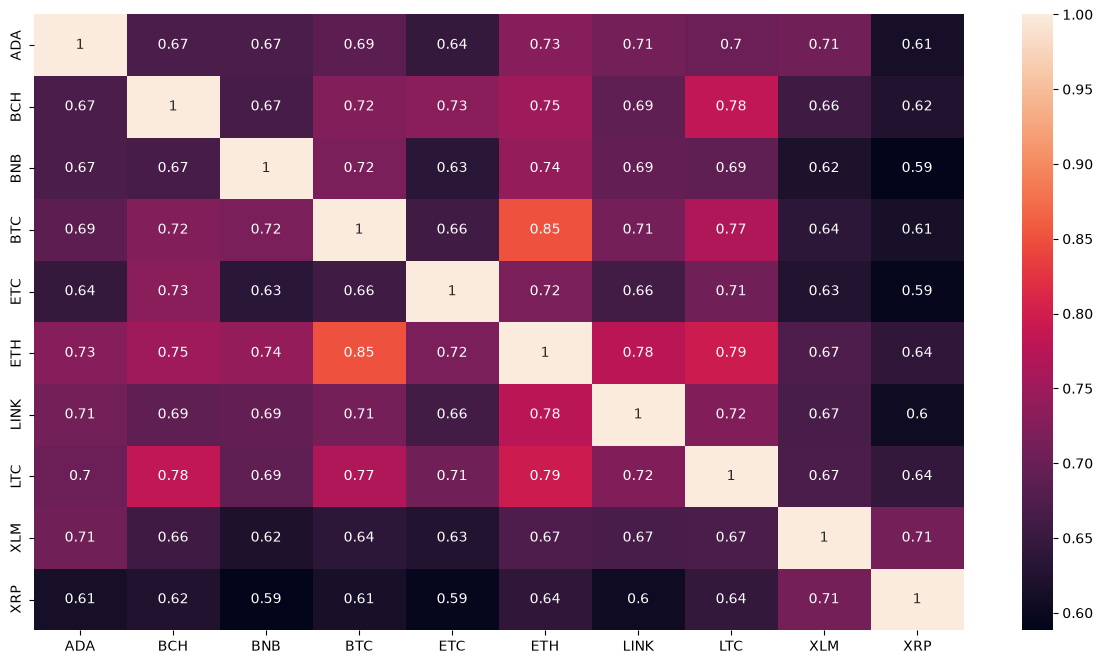

In [96]:
# Correlation matrix of the percentage change DataFrame
plt.figure(figsize=(15, 8))
sns.heatmap(df_pct.corr(), annot=True)
plt.show()

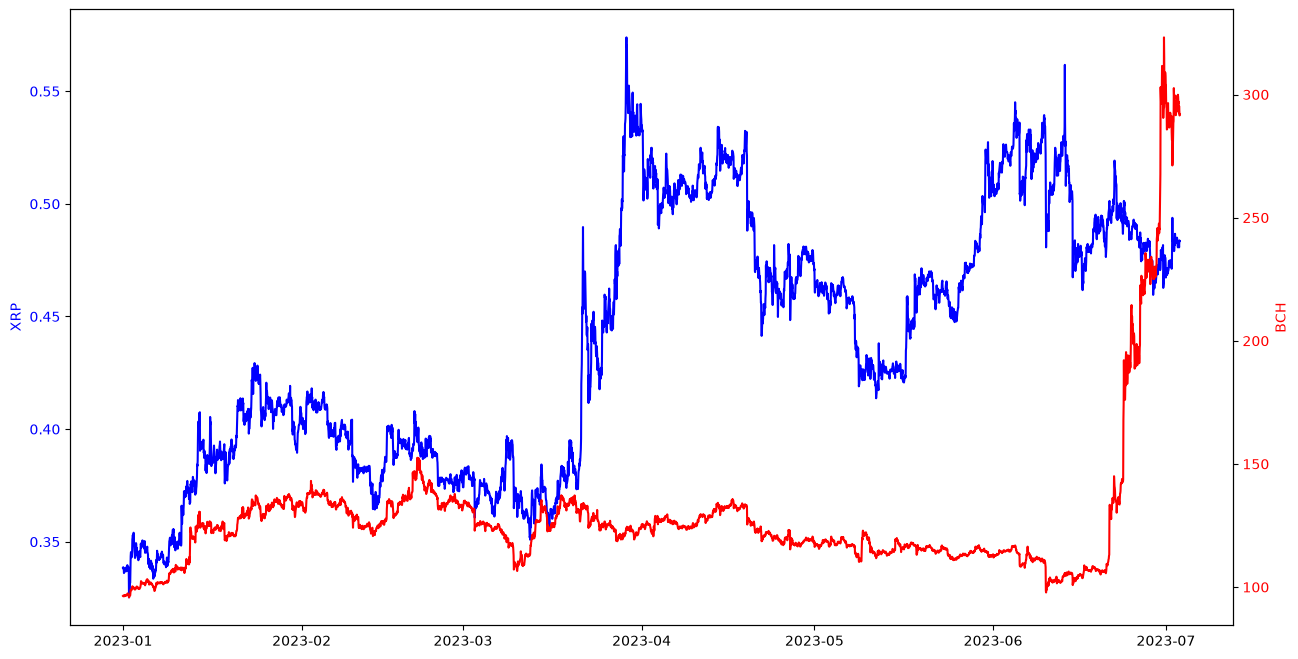

In [103]:
# Starting a new plot for the two assets
fix, ax = plt.subplots(figsize=(15, 8))

# Choose a specific year to plot the data for that year
data = df.loc['2023']
asset1 = 'XRP'
asset2 = 'BCH'

# Plot the first asset on the first axis
ax.plot(data.index, data[asset1], color='blue')
ax.set_ylabel(asset1, color='blue')
ax.tick_params(axis='y', labelcolor='blue')

# Create a second y-axis for the second asset
ax2 = ax.twinx()

# Plot the second asset on the second axis
ax2.plot(data.index, data[asset2], color='red')
ax2.set_ylabel(asset2, color='red')
ax2.tick_params(axis='y', labelcolor='red')
plt.show()


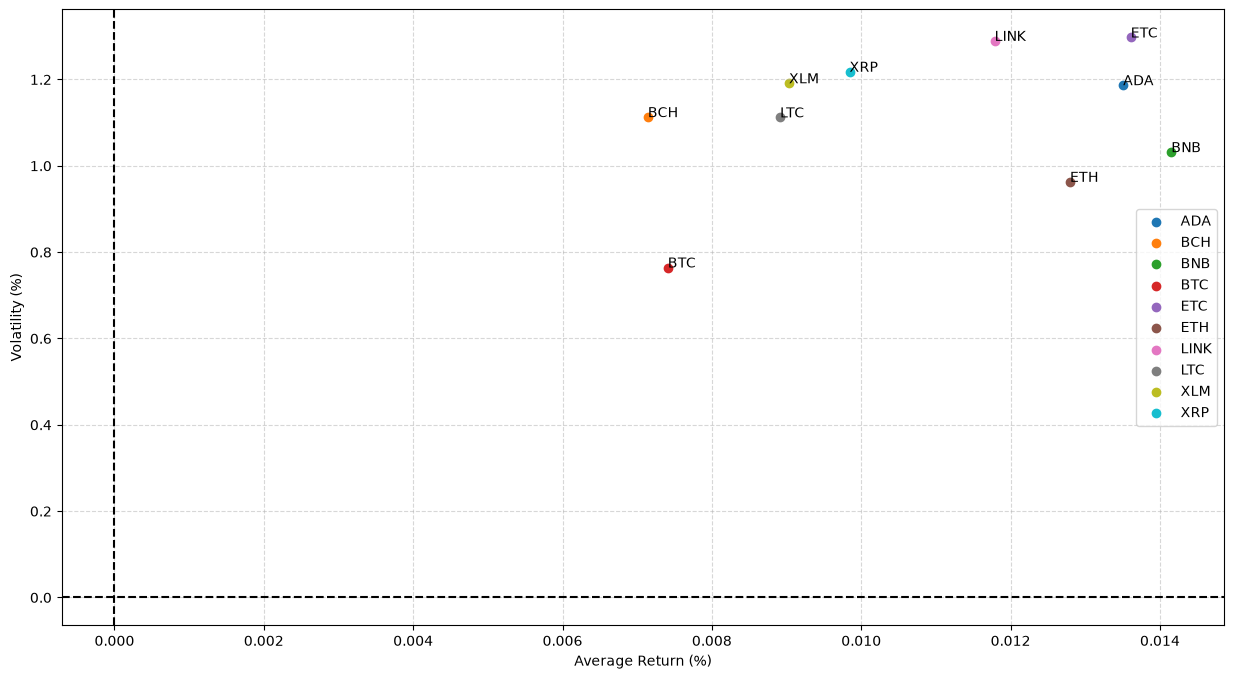

In [105]:
mean_return_list = []
volatility_list = []

temp_data = df_pct.loc[:]

fig, ax = plt.subplots(figsize=(15, 8))

for col in temp_data.columns:
    mean_return = temp_data[col].mean() * 100  # Calculate the mean return for the column and convert it to a percentage
    volatility = temp_data[col].std() * 100  # Calculate the standard deviation (volatility) for the column and convert it to a percentage
    mean_return_list.append(mean_return) # Append the mean return to the list
    volatility_list.append(volatility) # Append the volatility to the list
    
    ax.text(mean_return, volatility, col) # Add text labels to the plot at the mean return and volatility coordinates for each cryptocurrency
    ax.scatter(mean_return, volatility, label=col) # Create a scatter plot of mean return vs volatility for each cryptocurrency
    
ax.grid(True, linestyle='--', alpha=0.5) # Add a grid to the plot with dashed lines and some transparency
ax.axvline(0, color='black', linestyle='--') # Add a vertical line at x=0 to indicate the zero mean return
ax.axhline(0, color='black', linestyle='--') # Add a horizontal line at y=0 to indicate the zero volatility

ax.set_xlabel('Average Return (%)') # Set the x-axis label
ax.set_ylabel('Volatility (%)') # Set the y-axis label

ax.legend() # Add a legend to the plot to identify each cryptocurrency

plt.show()


ADA 1.0652078884048422
BCH 0.60079464454236
BNB 1.2838396574551911
BTC 0.9072830623877227
ETC 0.9818470857671784
ETH 1.2437204766487737
LINK 0.8555297403398743
LTC 0.7500566212544104
XLM 0.7096472501733638
XRP 0.7563949295619397


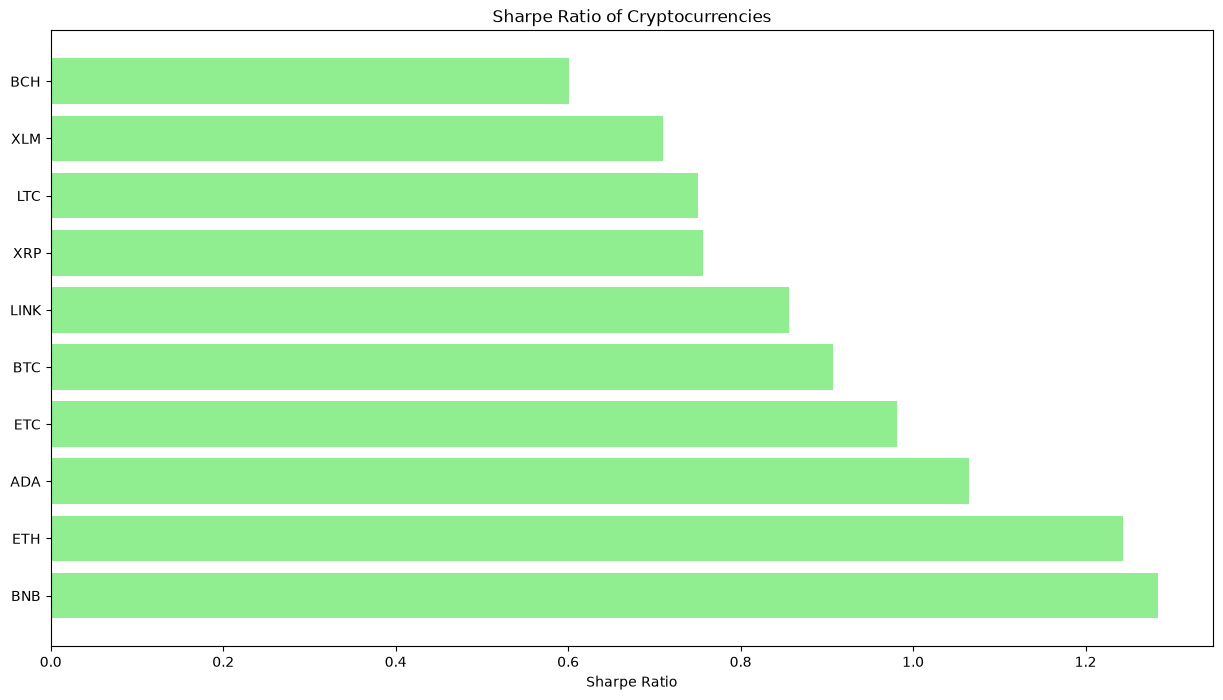

In [124]:

sharpe_ratios = []

# Calculating the Sharpe ratio for each cryptocurrency
temp_data = df_pct.loc[:]

for col in temp_data.columns:
    sharpe_ratio = (8760**0.5)*(temp_data[col].mean()/temp_data[col].std()) # Calculate the Sharpe ratio for each cryptocurrency
    sharpe_ratios.append(sharpe_ratio) # Append the Sharpe ratio to the list
    print(col, sharpe_ratio) # Print the cryptocurrency name and its corresponding Sharpe ratio
    
    

df_sharpe = pd.DataFrame(sharpe_ratios, index=temp_data.columns, columns=['Sharpe Ratio']) # Create a new DataFrame to store the Sharpe ratios for each cryptocurrency
df_sharpe = df_sharpe.sort_values(by='Sharpe Ratio', ascending=False) # Sort the DataFrame by the Sharpe ratio in descending order


plt.figure(figsize=(15, 8))
plt.barh(df_sharpe.index, df_sharpe['Sharpe Ratio'], color='lightgreen')# Create a horizontal bar plot of the Sharpe ratios for each cryptocurrency
plt.xlabel('Sharpe Ratio') # Set the x-axis label
plt.title('Sharpe Ratio of Cryptocurrencies') # Set the title of the plot
plt.show() # Display the plot


In [125]:
df

,ADA,BCH,BNB,BTC,ETC,ETH,LINK,LTC,XLM,XRP
date,,,,,,,,,,
2019-11-28 10:00:00,0.03861,218.98,15.8646,7478.58,3.9335,151.13,2.2359,47.23,0.05817,0.22530
2019-11-28 11:00:00,0.03885,219.04,15.8729,7479.54,3.9456,151.57,2.2518,47.36,0.05818,0.22601
2019-11-28 12:00:00,0.03850,217.53,15.6365,7444.12,3.9143,150.79,2.2173,46.84,0.05803,0.22497
2019-11-28 13:00:00,0.03846,218.29,15.6387,7455.67,3.9326,151.02,2.2101,46.91,0.05789,0.22482
2019-11-28 14:00:00,0.03875,218.67,15.7036,7459.51,3.9387,150.89,2.2335,47.03,0.05803,0.22514
...,...,...,...,...,...,...,...,...,...,...
2023-07-03 06:00:00,0.29230,292.50,247.2000,30651.25,20.1800,1947.85,6.5630,111.88,0.10850,0.48240
2023-07-03 07:00:00,0.29420,295.30,249.5000,30667.19,20.3400,1966.83,6.6330,112.34,0.10930,0.48070
2023-07-03 08:00:00,0.29480,293.70,248.6000,30640.12,20.1500,1960.02,6.6180,110.66,0.10730,0.48380


In [128]:
running_max = df['BTC'].cummax() # This will calculate the cumulative maximum of the BTC prices over time, which is useful for calculating drawdowns.
max_drawdown = (df['BTC'] - running_max) / running_max * 100 # This will calculate the maximum drawdown as a percentage, which is the percentage decline from the peak value to the trough value.
running_max


date
2019-11-28 10:00:00     7478.58
2019-11-28 11:00:00     7479.54
2019-11-28 12:00:00     7479.54
2019-11-28 13:00:00     7479.54
2019-11-28 14:00:00     7479.54
                         ...   
2023-07-03 06:00:00    68633.69
2023-07-03 07:00:00    68633.69
2023-07-03 08:00:00    68633.69
2023-07-03 09:00:00    68633.69
2023-07-03 10:00:00    68633.69
Name: BTC, Length: 31481, dtype: float64

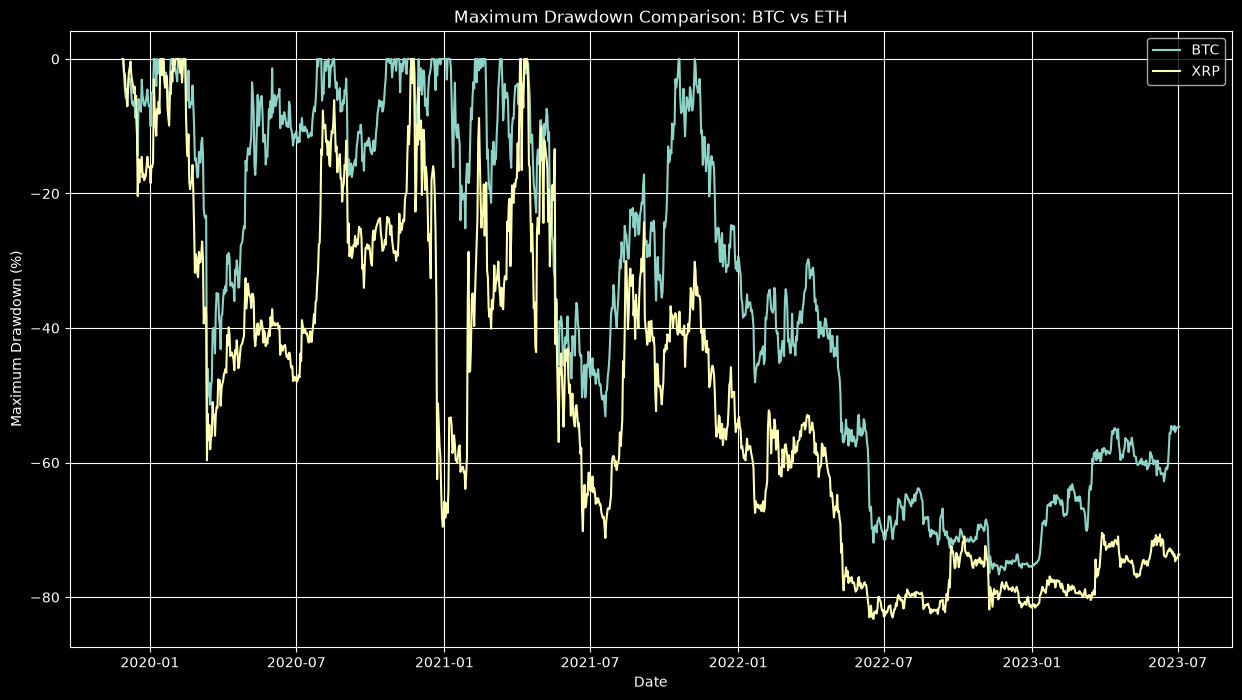

In [149]:
# Plotting comparisons of BTC and ETH drowndowns

plt.figure(figsize=(15, 8))
temp_data = df.resample('D').last() # Resample the data to daily frequency and take the last observation for each day
for col in ['BTC', 'XRP']:
    running_max = temp_data[col].cummax() # Calculate the cumulative maximum for each cryptocurrency
    max_drawdown = (temp_data[col] - running_max) / running_max * 100 # Calculate the maximum drawdown as a percentage
    plt.plot(max_drawdown, label=col) # Plot the maximum drawdown for each cryptocurrency


plt.title('Maximum Drawdown Comparison: BTC vs ETH') # Set the title of the plot
plt.xlabel('Date') # Set the x-axis label
plt.ylabel('Maximum Drawdown (%)') # Set the y-axis label
plt.legend() # Add a legend to the plot to identify each cryptocurrency 
plt.grid(True)
plt.show()


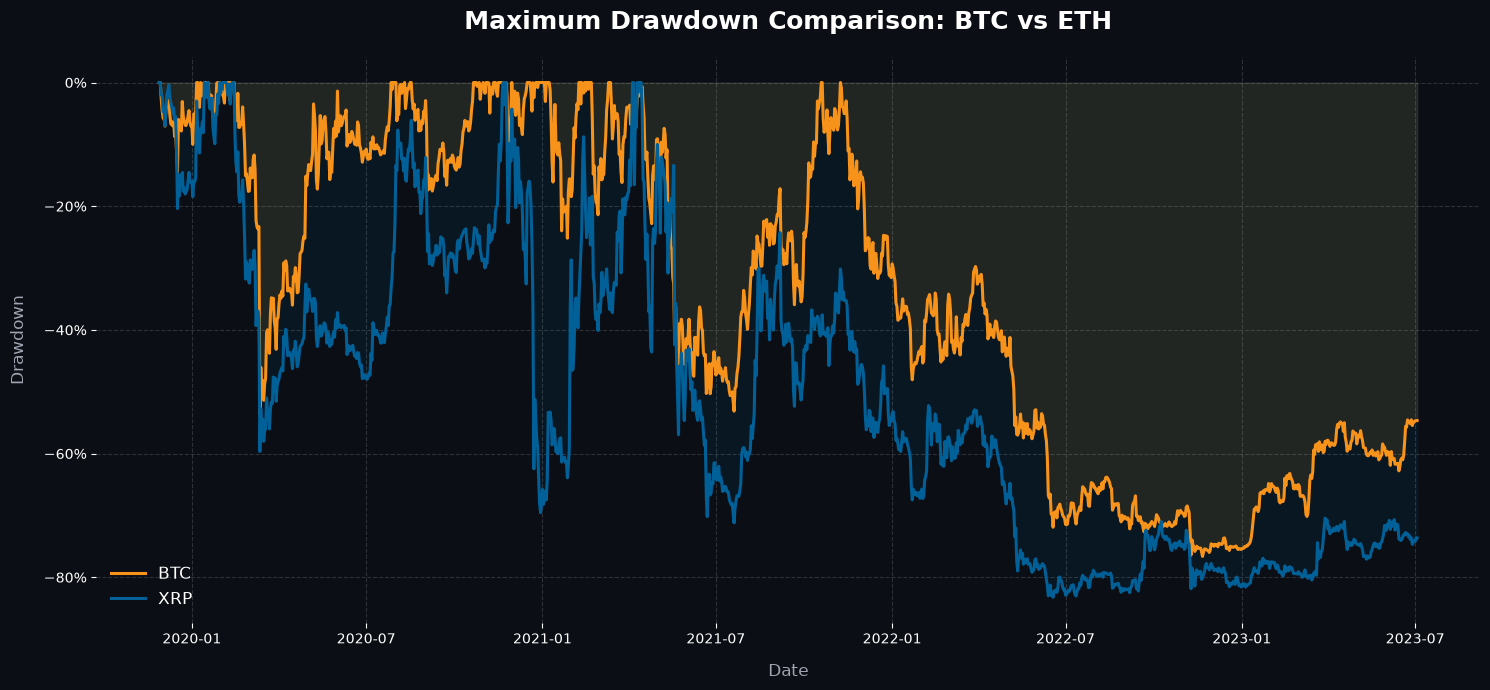

In [152]:
import matplotlib.pyplot as plt

# 1. Apply dark mode aesthetic
plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(15, 7), facecolor='#0B0E14')
ax.set_facecolor('#0B0E14')

# Resample data
temp_data = df.resample('D').last()

# Custom brand colors for BTC and ETH
colors = {
    'BTC': '#F7931A',  # Primary Color Orange
    'XRP': "#006097"   # Secondary Color Blue/Purple
}

# 2. Plot lines with shaded area underneath
for col in ['BTC', 'XRP']:
    running_max = temp_data[col].cummax()
    max_drawdown = (temp_data[col] - running_max) / running_max * 100
    
    # Draw sleek main line
    ax.plot(max_drawdown.index, max_drawdown, label=col, color=colors[col], linewidth=2.2)
    
    # Add subtle color glow under drawdown curve
    ax.fill_between(max_drawdown.index, max_drawdown, 0, color=colors[col], alpha=0.12)

# 3. Typography & Titles
ax.set_title('Maximum Drawdown Comparison: BTC vs ETH', fontsize=18, fontweight='bold', pad=20, color='#FFFFFF')
ax.set_xlabel('Date', fontsize=12, labelpad=12, color='#A0A5B1')
ax.set_ylabel('Drawdown', fontsize=12, labelpad=12, color='#A0A5B1')

# 4. Y-axis percentage formatting
ax.yaxis.set_major_formatter('{x:.0f}%')

# 5. Clean Grid & Spine Removal
ax.grid(True, linestyle='--', alpha=0.15, color='#FFFFFF')

# Remove top, right, left, and bottom outer borders
for spine in ax.spines.values():
    spine.set_visible(False)

# 6. Modern Frameless Legend
ax.legend(frameon=False, fontsize=12, loc='lower left')

plt.tight_layout()
plt.show()